In [227]:
%matplotlib inline 

In [228]:
import os
import io
import re
import itertools
import pandas as pd
import json

In [229]:
data_sources = ['mnd_TSC']

distr_dims = ['-'.join(['Distancegroup', 'Timeperiodseq']),
              '-'.join(['Distancegroup', 'Legs'])]

aggr_levels = ['lsoa']
sample_sizes = ['sample_perc_10']

export = True
out_folder = r'./outputs'
tolerance = 0.01

run_info = list(itertools.product(data_sources, distr_dims, aggr_levels, sample_sizes))

In [230]:
def prepare_results_filepaths(flpaths, run_results_fldr):

    flpaths['od'] = os.path.join(run_results_fldr, 'od_filtered.csv')
    flpaths['trs_mdl_descr'] = os.path.join(run_results_fldr, 'trs_mdl_descr.csv')
    flpaths['trs_mdl_info'] = os.path.join(run_results_fldr, 'trs_mdl_info.csv')
    flpaths['observed_distribution'] = os.path.join(run_results_fldr, 'target_distribution.csv')
    flpaths['optimisation_results'] = os.path.join(run_results_fldr, 'results.json')

    return flpaths

In [231]:
def get_optimisation_results(infilepath):
    with open(infilepath) as f:
        data = json.load(f)

        results = data['Solution'][1]['Variable']

        df_data = list()
        for chain, val in results.items():
            cid = re.search('\[(\d+)\]', chain, re.DOTALL).group(1)
            times_used = val['Value']
            df_data.append([int(cid), times_used])

        s = pd.DataFrame(df_data, columns=['Tourid', 'TimesUsed']).set_index('Tourid').squeeze()
        print('dtype of optimisation results before conversion to integer: {}'.format(s.dtype))
        s = s.astype(int)
        s = s[s>0]
        return s

In [232]:
def convert_optimisation_output_to_trips(trs_descr, optim_output):
    # Calculate how many times the tripchain has been used by the optimiser 
    df = trs_descr.join(optim_output, how='right')
    grpby_cols = ['Source', 'Target', 'Purpose', 'Timeperiod']
    optimisation_trips = df.groupby(grpby_cols)['TimesUsed'].sum().squeeze()
    optimisation_trips.name = 'ModelledTrips'
    return optimisation_trips


In [233]:
def get_modelled_trips(paths):
    
    trs_descr = pd.read_csv(paths['trs_mdl_descr'], index_col=['Tourid'])
    optim_output = get_optimisation_results(paths['optimisation_results'])
    
    if optim_output is not None:
        optimisation_trips = convert_optimisation_output_to_trips(trs_descr, optim_output)
        return optimisation_trips, optim_output
    else:
        return None

In [234]:
def prepare_ods_comparison(optim_ods, obs_ods):
    obs_ods.name = 'ObservedTrips'
    comp = obs_ods.to_frame().join(optim_ods)
    comp.columns.name = 'TripsSource'
    comp = comp.stack()
    comp.name = 'Trips'
    return comp

In [235]:
def get_input_params_from_folder(infldr):
    fldrs = [name for name in os.listdir(infldr) if os.path.isdir(os.path.join(infldr, name))]
    inputs = []
    for fldr in fldrs:
        matches = re.findall('(\d+)legs-over(\d+)trips-distrConstr(\w+)', fldr)
        if matches:
            legs = int(matches[0][0])
            trips = int(matches[0][1])
            if matches[0][2] == 'True':
                distr_constr_enabled = True
            elif matches[0][2] == 'False':
                distr_constr_enabled = False
            else:
                raise ValueError('distrConstrEnabled must be either True or False')
                
            inputs.append([legs, trips, distr_constr_enabled])
        
    return inputs

In [236]:
def prepare_ditribution_comparison(fldrpaths):
    trs_info = pd.read_csv(fldrpaths['trs_mdl_info'], index_col=['Tourid'])
    optim_output = get_optimisation_results(fldrpaths['optimisation_results'])
    observed_distr = pd.read_csv(fldrpaths['observed_distribution'], index_col='Distrgroupid')
    observed_distr.drop(columns=['Size'], inplace=True)

    df = trs_info.join(optim_output, how='right')
    optim_distr = df.groupby('Distrgroupid')['TimesUsed'].sum()
    optim_distr = optim_distr.div(optim_distr.sum())
    optim_distr.name = 'Percentage'
    
    # We need to identify the distribution dimensions cols (should be all apart form the Percentage)
    idx_cols = list()
    for c in observed_distr.columns:
        if c != 'Percentage':
            idx_cols.append(c)
    
    observed_distr.set_index(idx_cols, append=True, inplace=True)
    observed_distr = observed_distr.squeeze()
    
    distr_comp = observed_distr.to_frame().join(optim_distr, rsuffix='_')
    distr_comp.columns = ['Observed', 'Modelled']
    distr_comp.columns.name = 'Source'
    distr_comp = distr_comp.stack()
    distr_comp.name = 'Percentage'

    return distr_comp

In [237]:
def collapse_tour_legs(trs, leg_descr_cols):
    seqs = list()
    for c in leg_descr_cols:
        seq = trs.groupby('Tourid')[c].apply(tuple)
        seqs.append(seq)
    
    trs_collapsed = pd.concat(seqs, axis=1)
    
    return trs_collapsed

In [238]:
def prepare_descr_comparison(flpaths, mdl_nchains):
    trs_obs = pd.read_csv(flpaths['trs_obs_descr'], index_col=[0, 1])
    trs_mdl = pd.read_csv(flpaths['trs_mdl_descr'], index_col=[0, 1])

    # Standardising frames
    cmn_idx_names = ['Tourid', 'Legidx']
    trs_obs.index.names = cmn_idx_names
    trs_mdl.index.names = cmn_idx_names

    # Kepp only the used tripchains
    trs_mdl_used = trs_mdl.unstack().loc[mdl_nchains.index].stack()
    
    # Split Purpose in purpose and direction
    trs_mdl_used['Purpose'], trs_mdl_used['Direction'] = trs_mdl_used['Purpose'].str.split('_', 1).str

    leg_descr_cols = ['Source', 'Target', 'Purpose', 'Direction', 'Timeperiod']

    trs_obs_clpsd = collapse_tour_legs(trs_obs, leg_descr_cols)
    trs_mdl_clpsd = collapse_tour_legs(trs_mdl_used, leg_descr_cols)
    
    comp = pd.merge(left=trs_obs_clpsd.reset_index(), right=trs_mdl_clpsd.reset_index(),
                    on=leg_descr_cols, how='outer', suffixes=('_obs', '_mdl'),
                    indicator='Exist')
    
    comp.drop(columns=leg_descr_cols, inplace=True)
    comp = comp.squeeze()

    comp['Exist'] = comp['Exist'].str.replace('left_only', 'obs_only')
    comp['Exist'] = comp['Exist'].str.replace('right_only', 'mdl_only')

    return comp, trs_mdl_used

In [239]:
def include_run_info(df, d_run_params):
    try:
        df = df.to_frame()
    except AttributeError:
        pass
    
    for k, v in d_run_params.items():
        df[k] = v
        
    df.set_index(list(d_run_params.keys()), append=True, inplace=True)
    df = df.squeeze()
    return df

In [240]:
def prepare_run_info_dict(run_params):
    (data_source, distr_dims, aggr_level, sample_size,
     legs, trips_thresh, distr_constr_enabled) = run_params
    
    d_run_params = dict()
    d_run_params['DataSource'] = data_source
    d_run_params['AggrLevel'] = aggr_level
    d_run_params['SampleSize'] = sample_size
    d_run_params['DistrDims'] = distr_dims
    d_run_params['MaxLegs'] = int(legs)
    d_run_params['TripsThresh'] = int(trips_thresh)
    d_run_params['DistrConstr'] = distr_constr_enabled
    return d_run_params

In [241]:
def main(model_info):

    data_source, distr_dims, aggr_level, sample_size = model_info
    
    results_folder = r'../outputs/{}/{}/{}/{}'.format(data_source, distr_dims, aggr_level, sample_size)
    generation_inputs_fldr = r'../inputs/{}/{}/{}'.format(data_source, aggr_level, sample_size)

    params = get_input_params_from_folder(results_folder)

    concat_mdl_ods = list()
    concat_obs_ods = list()

    concat_trs_mdl_nchains = list()
    concat_trs_mdl_used_descr = list()

    concat_comp_distrs = list()
    concat_comp_descrs = list()

    flpaths = dict()
    flpaths['trs_obs_descr'] = os.path.join(generation_inputs_fldr, 'obs_trs_descr.csv')
    flpaths['trs_obs_info'] = os.path.join(generation_inputs_fldr, 'trs_obs_info.csv')
    trs_obs = pd.read_csv(flpaths['trs_obs_descr'], index_col=[0, 1])
    
    for legs, trips_thresh, distr_constr_enabled in params:
        print(aggr_level)
        print(legs, trips_thresh, distr_constr_enabled)
        run_info = model_info.copy()
        
        run_tmplt = '{}legs-over{}trips-distrConstr{}'.format(legs, trips_thresh, distr_constr_enabled)
        run_results_fldr = os.path.join(results_folder, run_tmplt)

        flpaths = prepare_results_filepaths(flpaths, run_results_fldr)

        mdl_od, mdl_nchains = get_modelled_trips(flpaths)

        if mdl_od is None:
            print('No results for legs:{}-trips:{}-distrConstr:{}'.format(legs, trips_thresh, distr_constr_enabled))
            continue

        comp_distr = prepare_ditribution_comparison(flpaths)
        comp_descr, trs_mdl_used_descr = prepare_descr_comparison(flpaths, mdl_nchains)

        idx_cols_od = ['Source', 'Target', 'Purpose', 'Timeperiod']
        obs_od = pd.read_csv(flpaths['od'], index_col=idx_cols_od)
        obs_od.drop(columns=['LegId'], inplace=True)

        run_info.extend([legs, trips_thresh, distr_constr_enabled])
        d_run_info = prepare_run_info_dict(run_info)
        
        obs_od = include_run_info(obs_od, d_run_info)
        mdl_od = include_run_info(mdl_od, d_run_info)
        mdl_nchains = include_run_info(mdl_nchains, d_run_info)
        trs_mdl_used_descr = include_run_info(trs_mdl_used_descr, d_run_info)
        comp_distr = include_run_info(comp_distr, d_run_info)
        comp_descr = include_run_info(comp_descr, d_run_info)

        concat_mdl_ods.append(mdl_od)
        concat_obs_ods.append(obs_od)
        concat_trs_mdl_nchains.append(mdl_nchains)
        concat_trs_mdl_used_descr.append(trs_mdl_used_descr)
        concat_comp_descrs.append(comp_descr)
        concat_comp_distrs.append(comp_distr)

    mdl_nchains = pd.concat(concat_trs_mdl_nchains)

    ods_mdl = pd.concat(concat_mdl_ods)
    ods_obs = pd.concat(concat_obs_ods)

    trs_mdl_used_descr = pd.concat(concat_trs_mdl_used_descr)

    comp_ods = prepare_ods_comparison(ods_mdl, ods_obs)
    comp_distrs = pd.concat(concat_comp_distrs)
    comp_descrs = pd.concat(concat_comp_descrs)
    
    return comp_ods, comp_distrs, comp_descrs

In [242]:
comparisons = dict()

ods = list()
distrs = list()
descrs = list()

for ri in run_info:
    comp_ods, comp_distrs, comp_descrs = main(list(ri))
    ods.append(comp_ods)
    distrs.append(comp_distrs)
    descrs.append(comp_descrs)

comparisons['ods'] = pd.concat(ods)
comparisons['distrs'] = pd.concat(distrs)
comparisons['descrs'] = pd.concat(descrs)

if export:
    #mdl_nchains.to_csv(os.path.join(out_folder, 'optimisation_results.csv'), header=True, index=True)
    comparisons['ods'].to_csv(os.path.join(out_folder, 'comparison_od.csv'), header=True)
    comparisons['distrs'].to_csv(os.path.join(out_folder, 'comparison_distributions.csv'), header=True, index=True)
    comparisons['descrs'].to_csv(os.path.join(out_folder, 'comparison_descrs.csv'), header=True, index=True)

lsoa
5 1 False
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64
lsoa
5 1 True
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64
lsoa
5 1 False
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64
lsoa
5 1 True
dtype of optimisation results before conversion to integer: float64
dtype of optimisation results before conversion to integer: float64


In [243]:
df = comparisons['distrs'].copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Source')
df['Diff_perc'] = df.Observed.sub(df.Modelled)

df['BelowTolerance'] = df.Diff_perc.abs() <= tolerance
df.dropna(inplace=True)
df['BelowTolerance'].all()

True

In [244]:
grpby_lvls = ['DataSource', 'DistrDims', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr',
              'TripsSource', 'Purpose']

df = comparisons['ods'].groupby(level=grpby_lvls).sum()

df = df.unstack('TripsSource')

df['Diff'] = df.ObservedTrips - df.ModelledTrips
df['Diff_perc'] = df.ModelledTrips/df.ObservedTrips - 1

df.style.format({
    'ModelledTrips': '{:,.0f}'.format,
    'ObservedTrips': '{:,.0f}'.format,
    'Diff': '{:,.0f}'.format,
    'Diff_perc': '{:.0%}'.format
})

In [245]:
filters = dict()
filters['DataSource'] = 'mnd_TSC'
filters['DistrDims'] = 'Distancegroup-Timeperiodseq'
filters['AggrLevel'] = 'lsoa'
filters['SampleSize'] = 'sample_perc_10'
filters['MaxLegs'] = 5
filters['TripsThresh'] = 1

In [246]:
if filters:
    comparisons_filt = dict()
    for k, f in comparisons.items():
        comparisons_filt[k] = comparisons[k].xs(list(filters.values()),
                                                level=list(filters.keys()))
    analysis_comp = comparisons_filt.copy()
else:
    analysis_comp = comparisons.copy()

False
True


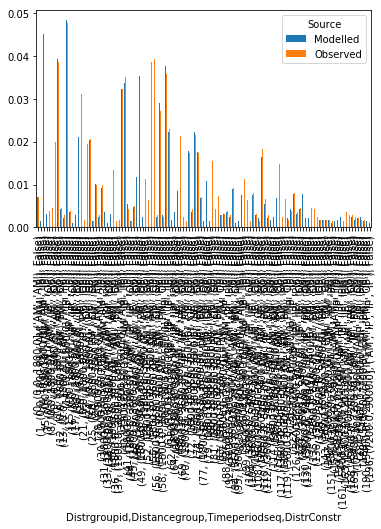

In [247]:
grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr']

grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]

dfg = analysis_comp['distrs'].groupby(level=grpby_lvls)
for k, g in dfg:
    print(k)
    plt = g.unstack('Source')
    plt.plot(kind='bar')

In [248]:
grpby_lvls = ['MaxLegs', 'TripsThresh', 'DistrConstr', 'Exist']
grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]

analysis_comp['descrs'].groupby(grpby_lvls).size().unstack('DistrConstr')

DistrConstr,False,True
Exist,,
both,2723,2744
mdl_only,242,223
obs_only,252,231
